# Thành viên 1 Dữ liệu và tiền xử lý ảnh

**Đầu vào duy nhất:** hai thư mục ảnh gốc `raw_dataset/` và `batch_dataset/`.
Notebook này kiểm kê, phát hiện ảnh lỗi/trùng, chia tập sơ bộ và xuất hai nhánh màu/xám.
Toàn bộ hàm xử lý được định nghĩa trong các ô bên dưới; không đọc mã từ file `.py`.

Chọn kernel Python của dự án, sau đó **Restart Kernel → Run All**.
Nếu thiếu thư viện, mở Terminal tại thư mục dự án và chạy `python -m pip install -r requirements.txt`.

## Phạm vi và tiêu chí

| Trục | Nhãn chính | Đặc trưng |
|---|---|---|
| Hình dạng | Nguyên, Vỡ, Không xác định | Chiều dài so với hạt nguyên tham chiếu |
| Màu sắc | Bình thường, Vàng, Sẫm, Không xác định | RGB/HSV và tỷ lệ pixel đổi màu |
| Kết cấu bổ trợ | Chưa đặt nhãn | Contrast, Homogeneity, Energy, Correlation từ GLCM |

Một hạt có thể vừa vỡ vừa vàng. Tên nhóm Tot/Kem/Te/Vo/Tap_chat là nhãn nguồn,
không phải nhãn chuẩn cho mọi hạt trong ảnh. Không xác định hạt lép từ ảnh trên xuống.
Các ngưỡng chất lượng ở notebook 04 chỉ là cấu hình thử nghiệm, không dùng ML.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from types import SimpleNamespace
import os
import json
import hashlib
import math
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage.morphology import h_maxima
from skimage.feature import graycoprops
from IPython.display import display, Markdown

# Mặc định: đặt notebook cạnh raw_dataset và batch_dataset.
# Có thể đổi PROJECT_ROOT sang đường dẫn thư mục dữ liệu của bạn.
PROJECT_ROOT = Path(os.environ.get("RICE_DATA_ROOT", Path.cwd())).resolve()
OUTPUT_ROOT = Path(os.environ.get("RICE_OUTPUT_ROOT", PROJECT_ROOT / "outputs" / "notebook")).resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

## Cấu hình tiền xử lý

Resize giữ tỷ lệ, không phóng to ảnh nhỏ. Nhánh màu chỉ resize để đo RGB/HSV.
Nhánh xám dùng Gaussian và tùy chọn tương phản. `none` là mặc định;
chỉ chọn `equalize` hoặc `clahe` sau khi quan sát ảnh.

In [2]:
MAX_SIDE = 1600
BLUR_KERNEL = 3
CONTRAST = "none"  # none, equalize, clahe
STAGE1 = OUTPUT_ROOT / "01_du_lieu"
STAGE1.mkdir(parents=True, exist_ok=True)
for folder in ["raw_dataset", "batch_dataset"]:
    if not (PROJECT_ROOT / folder).is_dir():
        raise FileNotFoundError(f"Thiếu thư mục ảnh gốc {folder}. Hãy chỉnh PROJECT_ROOT.")

## Hàm đọc ghi ảnh và tiền xử lý

In [3]:
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

def decode_image(data: bytes) -> np.ndarray:
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('Không đọc được ảnh. Hãy dùng ảnh JPG, PNG, BMP hoặc TIFF hợp lệ.')
    return image

def read_image(path) -> np.ndarray:
    return decode_image(Path(path).read_bytes())

def write_image(path, image: np.ndarray) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, encoded = cv2.imencode(path.suffix, image)
    if not ok:
        raise OSError(f'Không mã hóa được ảnh {path}')
    path.write_bytes(encoded.tobytes())

In [4]:
@dataclass
class PreprocessingResult:
    color: np.ndarray
    gray: np.ndarray
    denoised: np.ndarray
    enhanced: np.ndarray
    scale_x: float
    scale_y: float
    original_shape: tuple

def preprocess_image(image, max_side=1600, blur_kernel=3, contrast='none'):
    if not isinstance(image, np.ndarray) or image.dtype != np.uint8 or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError('Ảnh phải là mảng BGR uint8 có 3 kênh.')
    if max_side < 32 or blur_kernel < 1 or blur_kernel % 2 == 0:
        raise ValueError('max_side >= 32; nhân Gaussian phải là số lẻ dương.')
    if contrast not in {'none', 'equalize', 'clahe'}:
        raise ValueError('contrast phải là none, equalize hoặc clahe.')
    h, w = image.shape[:2]
    scale = min(1.0, float(max_side) / max(h, w))
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    color = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_AREA) if scale < 1 else image.copy()
    gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
    denoised = cv2.GaussianBlur(gray, (blur_kernel, blur_kernel), 0)
    enhanced = denoised.copy()
    if contrast == 'equalize':
        enhanced = cv2.equalizeHist(denoised)
    elif contrast == 'clahe':
        enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(denoised)
    return PreprocessingResult(color, gray, denoised, enhanced, nw / w, nh / h, (h, w))

## Kiểm kê và xuất dữ liệu bàn giao

So sánh nội dung pixel đã giải mã để phát hiện ảnh trùng, kể cả khi tên hoặc định dạng khác nhau.
Giữ nguyên toàn bộ ảnh nguồn. Mỗi ảnh duy nhất được xuất thành PNG màu và PNG xám.
Đường dẫn trong manifest tính tương đối từ `01_du_lieu/`, không gắn cố định với một máy.

Chia calibration/test theo ảnh bằng hàm băm chỉ là bước sơ bộ; vẫn cần gom các ảnh cùng phiên chụp
trước khi đánh giá độc lập. Không dùng tập test để đặt ngưỡng.

In [5]:
def prepare_original_images():
    rows, seen = [], {}
    paths = sorted(
        p for group in ["raw_dataset", "batch_dataset"]
        for p in (PROJECT_ROOT / group).rglob("*")
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    )
    if not paths:
        raise ValueError("Không tìm thấy ảnh gốc.")
    for i, path in enumerate(paths, 1):
        relative = path.relative_to(PROJECT_ROOT).as_posix()
        row = dict(image_id="", image_path=relative, source_group=path.parent.name,
                   file_sha256=hashlib.sha256(path.read_bytes()).hexdigest(), pixel_sha256="",
                   original_width=0, original_height=0, status="error", duplicate_of="", split="",
                   color_path="", gray_path="", scale_x=0.0, scale_y=0.0,
                   max_side=MAX_SIDE, blur_kernel=BLUR_KERNEL, contrast=CONTRAST, error="")
        try:
            image = read_image(path)
            digest = hashlib.sha256(str(image.shape).encode() + image.tobytes()).hexdigest()
            row.update(image_id=digest[:16], pixel_sha256=digest,
                       original_width=image.shape[1], original_height=image.shape[0], status="ok",
                       split="test" if int(digest[:8], 16) % 5 == 0 else "calibration")
            if digest in seen:
                row["duplicate_of"] = seen[digest]
            else:
                seen[digest] = relative
                pre = preprocess_image(image, MAX_SIDE, BLUR_KERNEL, CONTRAST)
                color_path = STAGE1 / "color" / f"{row['image_id']}.png"
                gray_path = STAGE1 / "gray" / f"{row['image_id']}.png"
                write_image(color_path, pre.color)
                write_image(gray_path, pre.enhanced)
                row.update(color_path=color_path.relative_to(STAGE1).as_posix(),
                           gray_path=gray_path.relative_to(STAGE1).as_posix(),
                           scale_x=pre.scale_x, scale_y=pre.scale_y)
        except (ValueError, OSError) as exc:
            row["status"] = "error"
            row["error"] = str(exc)
        rows.append(row)
        if i % 10 == 0 or i == len(paths):
            print(f"Đã kiểm tra {i}/{len(paths)} ảnh")
    manifest = pd.DataFrame(rows)
    valid = manifest[(manifest.status == "ok") & (manifest.duplicate_of == "")]
    manifest.to_csv(STAGE1 / "manifest.csv", index=False, encoding="utf-8-sig")
    for split in ["calibration", "test"]:
        valid[valid.split == split].to_csv(STAGE1 / f"{split}_images.csv", index=False, encoding="utf-8-sig")
    audit = dict(total_files=len(manifest), readable=int((manifest.status == "ok").sum()),
                 duplicate_files=int((manifest.duplicate_of != "").sum()), unique_images=len(valid),
                 calibration_images=int((valid.split == "calibration").sum()), test_images=int((valid.split == "test").sum()),
                 verified_real_grain_labels=0,
                 preprocessing=dict(max_side=MAX_SIDE, blur_kernel=BLUR_KERNEL, contrast=CONTRAST))
    (STAGE1 / "audit.json").write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding="utf-8")
    return manifest, valid, audit

manifest, valid_images, audit = prepare_original_images()
display(pd.DataFrame([audit]).drop(columns="preprocessing"))
display(manifest[["image_path", "status", "duplicate_of", "split"]].head(10))

Đã kiểm tra 10/69 ảnh
Đã kiểm tra 20/69 ảnh
Đã kiểm tra 30/69 ảnh
Đã kiểm tra 40/69 ảnh
Đã kiểm tra 50/69 ảnh
Đã kiểm tra 60/69 ảnh
Đã kiểm tra 69/69 ảnh


,total_files,readable,duplicate_files,unique_images,calibration_images,test_images,verified_real_grain_labels
0,69,69,2,67,58,9,0


,image_path,status,duplicate_of,split
0,batch_dataset/picCacloaigao (1).jpg,ok,,calibration
1,batch_dataset/picCacloaigao (10).jpg,ok,,calibration
2,batch_dataset/picCacloaigao (11).jpg,ok,,calibration
3,batch_dataset/picCacloaigao (12).jpg,ok,,calibration
4,batch_dataset/picCacloaigao (13).jpg,ok,batch_dataset/picCacloaigao (12).jpg,calibration
5,batch_dataset/picCacloaigao (14).jpg,ok,,calibration
6,batch_dataset/picCacloaigao (15).jpg,ok,batch_dataset/picCacloaigao (14).jpg,calibration
7,batch_dataset/picCacloaigao (16).jpg,ok,,calibration
8,batch_dataset/picCacloaigao (17).jpg,ok,,calibration
9,batch_dataset/picCacloaigao (18).jpg,ok,,calibration


## Quan sát ảnh gốc và các phương án tiền xử lý

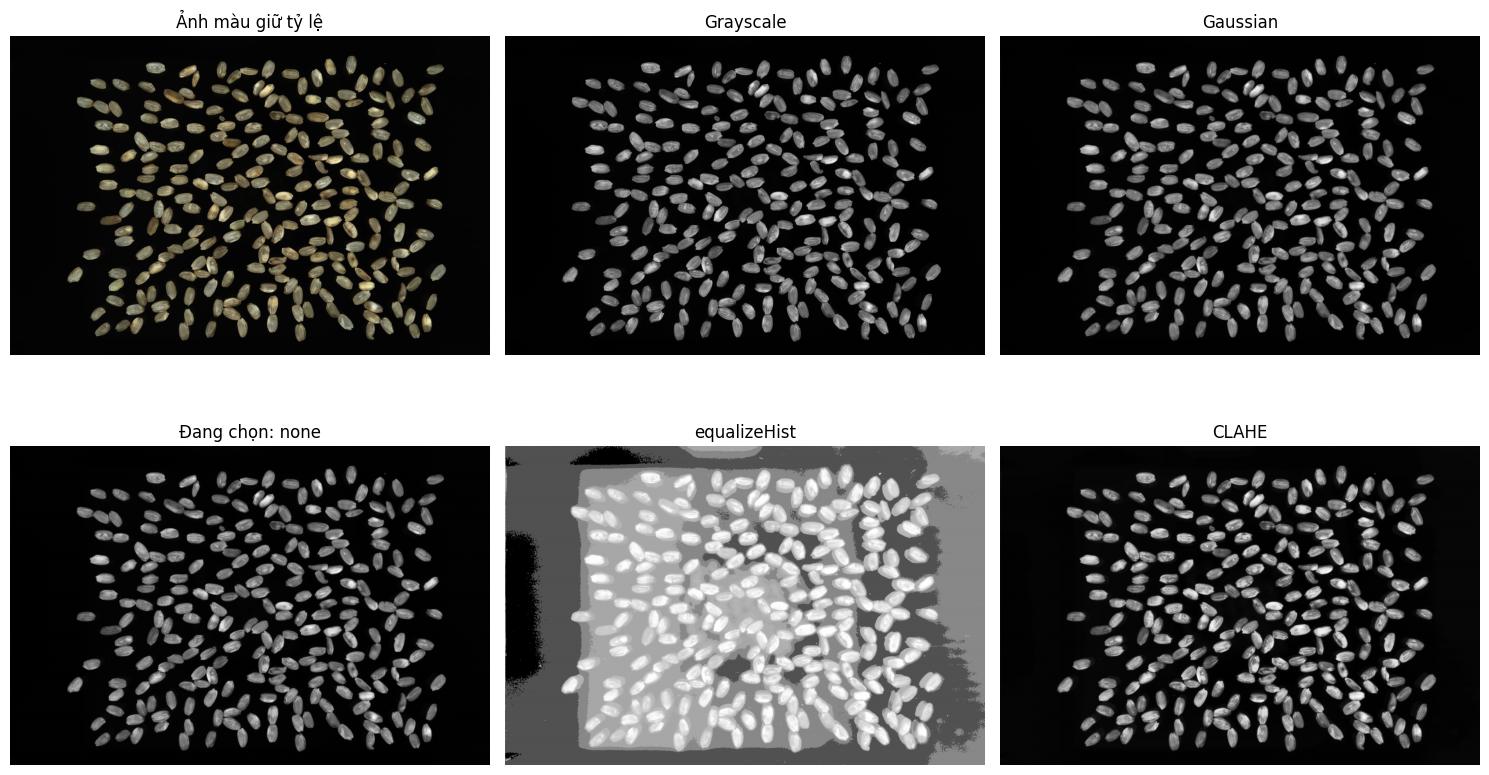

Ảnh minh họa: raw_dataset/Tot/picT (1).png
Kích thước gốc: (3644, 5480) - sau resize: (1064, 1600)


In [6]:
demo_rows = valid_images[valid_images.image_path == "raw_dataset/Tot/picT (1).png"]
demo = (demo_rows if len(demo_rows) else valid_images).iloc[0]
original = read_image(PROJECT_ROOT / demo.image_path)
pre = preprocess_image(original, MAX_SIDE, BLUR_KERNEL, CONTRAST)
views = [
    (cv2.cvtColor(pre.color, cv2.COLOR_BGR2RGB), "Ảnh màu giữ tỷ lệ"),
    (pre.gray, "Grayscale"), (pre.denoised, "Gaussian"),
    (pre.enhanced, f"Đang chọn: {CONTRAST}"),
    (preprocess_image(original, MAX_SIDE, BLUR_KERNEL, "equalize").enhanced, "equalizeHist"),
    (preprocess_image(original, MAX_SIDE, BLUR_KERNEL, "clahe").enhanced, "CLAHE"),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (view, title) in zip(axes.flat, views):
    ax.imshow(view, cmap="gray" if view.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Ảnh minh họa:", demo.image_path)
print("Kích thước gốc:", original.shape[:2], "- sau resize:", pre.color.shape[:2])

## Kiểm tra và bàn giao cho thành viên 2

Sản phẩm: `outputs/notebook/01_du_lieu/manifest.csv`, hai thư mục `color/`, `gray/`,
danh sách calibration/test và `audit.json`. Ảnh trùng chỉ được ghi nhận, không xử lý lặp.
Mở notebook 02 bằng một kernel mới và chạy từ đầu. Không cần giữ biến của notebook 01.

In [7]:
assert len(valid_images) > 0
assert valid_images.image_id.is_unique
assert all((STAGE1 / p).is_file() for p in valid_images.color_path)
assert all((STAGE1 / p).is_file() for p in valid_images.gray_path)
probe = np.zeros((120, 240, 3), np.uint8)
probe_pre = preprocess_image(probe, max_side=120)
assert probe_pre.color.shape[:2] == (60, 120)
assert probe_pre.scale_x == probe_pre.scale_y
print("Đạt: dữ liệu bàn giao tồn tại, không lặp ảnh và resize giữ tỷ lệ.")

Đạt: dữ liệu bàn giao tồn tại, không lặp ảnh và resize giữ tỷ lệ.
